In [40]:
# importing packages
import numpy as np
import pandas as pd
import yfinance as yf
import matplotlib.pyplot as plt
import scipy as sp
import seaborn as sn
import warnings
warnings.simplefilter("ignore")

I'm curious how the minimum variance and maximum Sharpe ratio portfolios (discussed in 00_efficient_frontier) move when more historical data is avaliable. By using the same approach as in 00, I would like to investigate this.

In [41]:
symbols = ['XDWT.DE', 'XDWI.DE', 'XDW0.DE', 'XDWH.DE', 'XDWF.DE', 'XDWC.DE', 'XWTS.DE', 'XDWS.DE'] # Sector ETFs from Xtrackers
n = len(symbols)
for symbol in symbols:
    info = yf.Ticker(symbol).info
    print(f"{symbol}: {info.get('longName', 'N/A')}")

datasets = {}
years = [2024, 2023, 2022, 2021, 2020, 2019, 2018]
for year in years:
    raw_data = yf.download(symbols, start = f'{year}-01-01')
    data = raw_data['Close']
    datasets[year] = data

XDWT.DE: Xtrackers MSCI World Information Technology UCITS ETF 1C
XDWI.DE: Xtrackers MSCI World Industrials UCITS ETF 1C
XDW0.DE: Xtrackers MSCI World Energy UCITS ETF 1C
XDWH.DE: Xtrackers MSCI World Health Care UCITS ETF 1C
XDWF.DE: Xtrackers MSCI World Financials UCITS ETF 1C
XDWC.DE: Xtrackers MSCI World Consumer Discretionary UCITS ETF 1C
XWTS.DE: Xtrackers MSCI World Communication Services UCITS ETF 1C


[************          25%                       ]  2 of 8 completed

XDWS.DE: Xtrackers MSCI World Consumer Staples UCITS ETF 1C


[*********************100%***********************]  8 of 8 completed
[*********************100%***********************]  8 of 8 completed
[*********************100%***********************]  8 of 8 completed
[*********************100%***********************]  8 of 8 completed
[*********************100%***********************]  8 of 8 completed
[*********************100%***********************]  8 of 8 completed
[*********************100%***********************]  8 of 8 completed


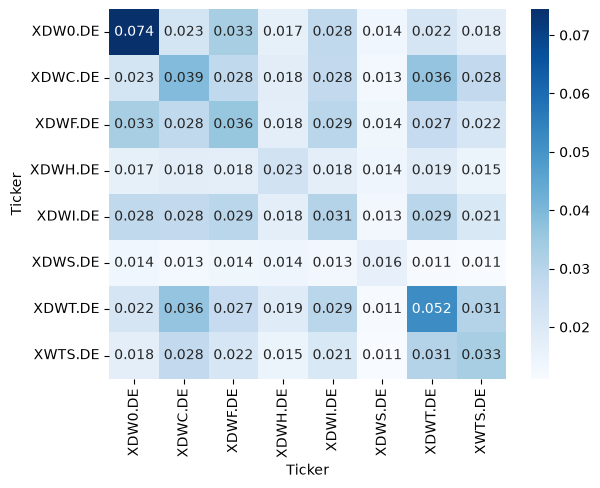

In [42]:
returns = {year: df.pct_change().dropna() for year, df in datasets.items()}
cov_matrix = {year: df.cov() * 252 for year, df in returns.items()} # Annualised
mean_returns = {year: df.mean() * 252 for year, df in returns.items()} # Annualised

sn.heatmap(cov_matrix[2018], annot=True, fmt='.3f', cmap='Blues')
plt.show()

In [43]:
random_weights = np.random.dirichlet(np.ones(n), size=500000).T # Dirichlet distribution to ensure weights sum to 1, while being random.

portfolio_returns = {year: random_weights.T @ mean_returns[year] for year, df in datasets.items()}
portfolio_variance = {year: np.einsum('ij,jk,ik->i', random_weights.T, cov_matrix[year], random_weights.T) for year, df in datasets.items()} # einsum for computation speed
portfolio_volatility = {year: np.sqrt(var) for year, var in portfolio_variance.items()}

In [44]:
rf = 0.0225 # ECB rate

wmv = {year: sp.optimize.minimize(lambda w: w.T @ cov_matrix[year] @ w, x0 = np.ones(n) / n, bounds=[(0, 1)] * n, constraints={'type': 'eq', 'fun': lambda w: np.sum(w) - 1}) for year in datasets}
wms = {year: sp.optimize.minimize(lambda w: -w.T @ (mean_returns[year] - rf) / (np.sqrt(w.T @ cov_matrix[year] @ w)), x0 = np.ones(n) / n, bounds=[(0, 1)] * n, constraints={'type': 'eq', 'fun': lambda w: np.sum(w) - 1}) for year in datasets}

wmv_return = {year: wmv[year].x.T @ mean_returns[year] for year in datasets}
wmv_volatility = {year: np.sqrt(wmv[year].x.T @ cov_matrix[year] @ wmv[year].x) for year in datasets}
wms_return = {year: wms[year].x.T @ mean_returns[year] for year in datasets}
wms_volatility = {year: np.sqrt(wms[year].x.T @ cov_matrix[year] @ wms[year].x) for year in datasets}



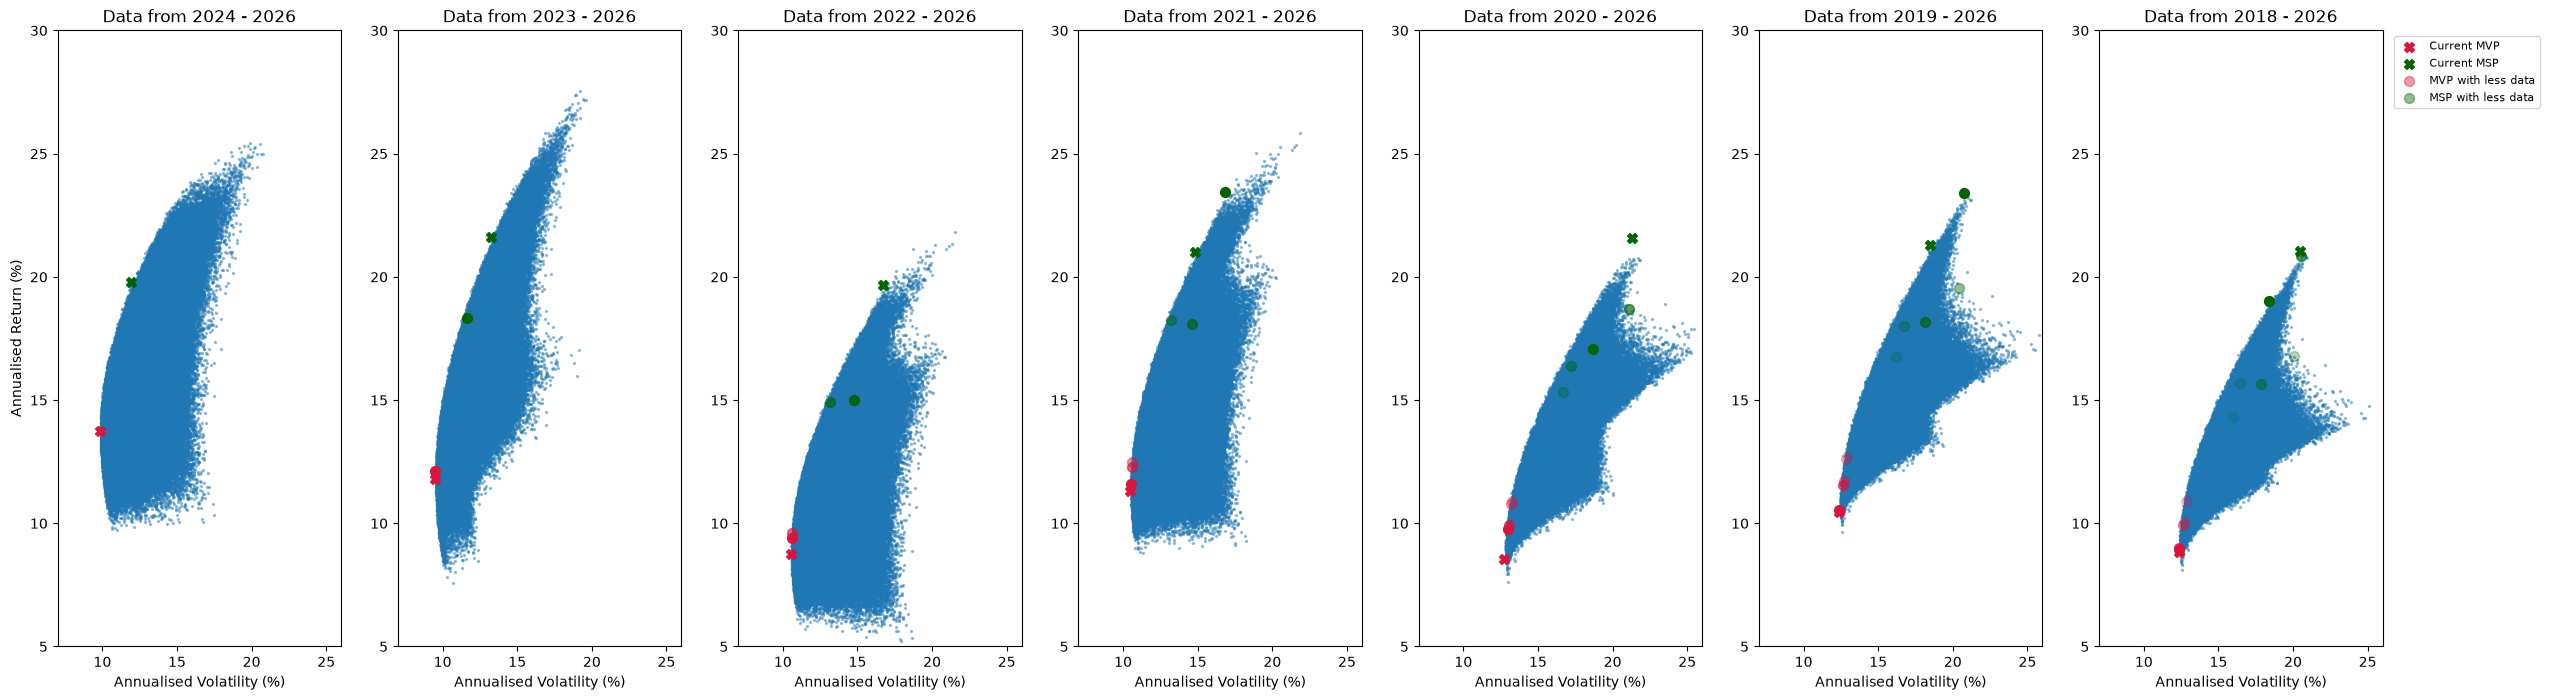

In [70]:
plt.figure(figsize=(30, 8))
wmv_returnold = {}
wmv_volatilityold = {}
wms_returnold = {}
wms_volatilityold = {}

for i, year in enumerate(datasets, start = 1):
    plt.subplot(1, 7, i)
    plt.scatter(portfolio_volatility[year] * 100, portfolio_returns[year] * 100, s=2, alpha=0.4)
    plt.scatter(wmv_volatility[year] * 100, wmv_return[year] * 100, s=50, c='crimson', marker='X', label='Current MVP')
    plt.scatter(wms_volatility[year] * 100, wms_return[year] * 100, s=50, c='darkgreen', marker='X', label='Current MSP')
    for j in range(1, 7):
        if year + j in datasets:
            wmv_returnold[year + j] = wmv[year + j].x.T @ mean_returns[year]
            wmv_volatilityold[year + j] = np.sqrt(wmv[year + j].x.T @ cov_matrix[year] @ wmv[year + j].x)
            wms_returnold[year + j] = wms[year + j].x.T @ mean_returns[year]
            wms_volatilityold[year + j] = np.sqrt(wms[year + j].x.T @ cov_matrix[year] @ wms[year + j].x)
            plt.scatter(wmv_volatilityold[year + j] * 100, wmv_returnold[year + j] * 100, s=50, c='crimson', alpha = 0.65 ** (j - 1), marker='o', label='MVP with less data' if j == 3 else None)
            plt.scatter(wms_volatilityold[year + j] * 100, wms_returnold[year + j] * 100, s=50, c='darkgreen', alpha = 0.65 ** (j - 1), marker='o', label='MSP with less data' if j == 3 else None)
    plt.xlim(7, 26)
    plt.ylim(5, 30)
    plt.xlabel('Annualised Volatility (%)')
    plt.ylabel('Annualised Return (%)' if i == 1 else None)
    plt.title(f'Data from {year} - 2026')

plt.legend(bbox_to_anchor=(1.02, 1), loc='upper left', fontsize=8)
plt.savefig('../images/01_0.png', dpi=200, bbox_inches='tight')
plt.show()

The minimum variance portfolios stays somewhat efficient, with less data, the volatility is underestimated. The maximum Sharpe ratio portfolios changes more over time, but more so in clusters. In the plot it is visible that the maximum Sharpe ratio portfolios remain close together when the start date of the data are close to each other. 

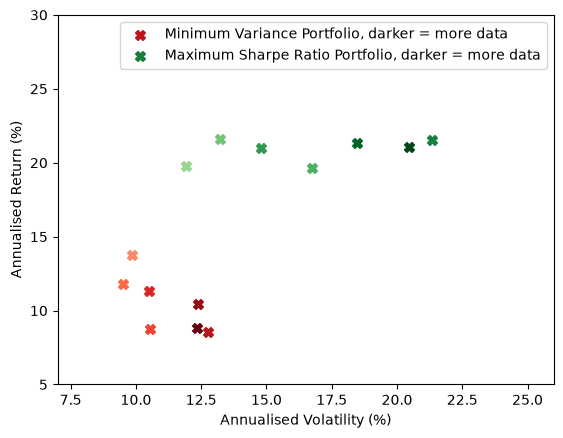

In [55]:
cmap_mv = plt.cm.Reds
cmap_ms = plt.cm.Greens
shades = np.linspace(0.4, 1.0, len(datasets))

for shade, year in zip(shades, datasets):
    plt.scatter(wmv_volatility[year] * 100, wmv_return[year] * 100, s=50, c=cmap_mv(shade), marker='X', label='Minimum Variance Portfolio, darker = more data' if shade == shades[4] else None)
    plt.scatter(wms_volatility[year] * 100, wms_return[year] * 100, s=50, c=cmap_ms(shade), marker='X', label='Maximum Sharpe Ratio Portfolio, darker = more data' if shade == shades[4] else None)
    plt.xlim(7, 26)
    plt.ylim(5, 30)
    plt.xlabel('Annualised Volatility (%)')
    plt.ylabel('Annualised Return (%)')

plt.legend()
plt.savefig('../images/01_1.png', dpi=200, bbox_inches='tight')
plt.show()

The minimum variance portfolios cluster together, where the volatility slowly rises as more data is added. The maximum Sharpe ratio portfolios have a clear pattern, where the return remains somewhat equal, while the volatility rises as more data is added.

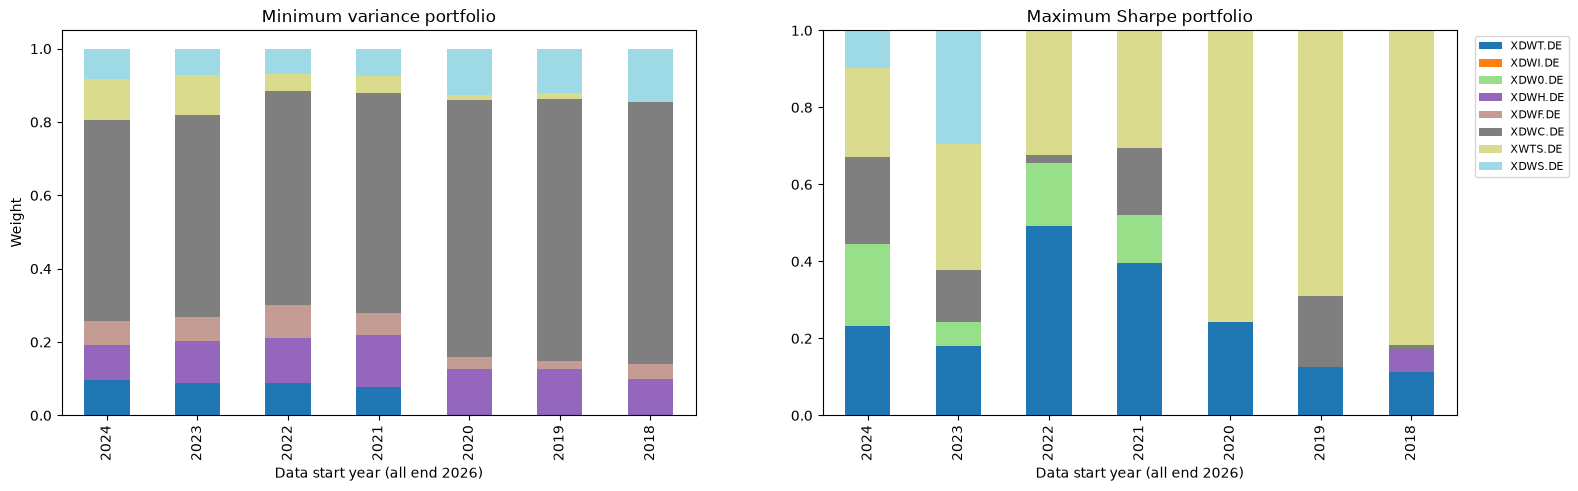

In [73]:
w_ms = pd.DataFrame({year: wms[year].x for year in years}, index=symbols).T
w_mv = pd.DataFrame({year: wmv[year].x for year in years}, index=symbols).T

plt.figure(figsize=(18, 5))

plt.subplot(1, 2, 1)
w_mv.plot(kind='bar', stacked=True, colormap='tab20', ax=plt.gca(), legend=False)
plt.title('Minimum variance portfolio')
plt.xlabel('Data start year (all end 2026)')
plt.ylabel('Weight')

plt.subplot(1, 2, 2)
w_ms.plot(kind='bar', stacked=True, colormap='tab20', ax=plt.gca())
plt.title('Maximum Sharpe portfolio')
plt.xlabel('Data start year (all end 2026)')
plt.legend(bbox_to_anchor=(1.02, 1), loc='upper left', fontsize=8)

plt.savefig('../images/01_2.png', dpi=200, bbox_inches='tight')
plt.show()

The minimum variance portfolios have very minimal asset changes over time, which suggests that these portfolios are less sensitive to changes in historical data. The maximum Sharpe ratio portfolios show more variation in assets, with a big difference between 2020 and 2021. Overall, it seems as the portfolio stablizes with more data added, while with less data the portfolio allocation seems more volatile.